We load the data into python

In [1]:
import pandas as pd

df = pd.read_csv("member_votes.csv")

print(df.head())
print(df.shape)
print(df.columns)

   vote_id  member_id      position country_code group_code group_short_label  \
0   108425        840  DID_NOT_VOTE          LUX      RENEW             Renew   
1   108425       1394       AGAINST          GBR      RENEW             Renew   
2   108425       1854    ABSTENTION          DEU         SD               S&D   
3   108425       1909    ABSTENTION          DEU         SD               S&D   
4   108425       1913    ABSTENTION          DEU         SD               S&D   

   national_party_id national_party_short_label  
0             5284.0                         DP  
1             5236.0                         LD  
2             5196.0                        SPD  
3             5196.0                        SPD  
4             5196.0                        SPD  
(18219850, 8)
Index(['vote_id', 'member_id', 'position', 'country_code', 'group_code',
       'group_short_label', 'national_party_id', 'national_party_short_label'],
      dtype='str')


We now explore the dataset

In [2]:

print("Number of voting records:", len(df))

print("Number of unique MEPs:")
print(df["member_id"].nunique())

print("Number of parliamentary votes:")
print(df["vote_id"].nunique())

print("Voting positions:")
print(df["position"].value_counts())


Number of voting records: 18219850
Number of unique MEPs:
1275
Number of parliamentary votes:
25688
Voting positions:
position
FOR             9040638
AGAINST         6663189
DID_NOT_VOTE    1603721
ABSTENTION       912302
Name: count, dtype: int64


During development, it is easier to work with a few hundred parliamentary votes, so we select a smaller data set. We're selecting 300 unique parliamentary vote IDs and keeping all individual MEP records associated with them.

In [3]:

# Select 300 distinct parliamentary vote IDs
vote_ids = (
    df["vote_id"]
    .drop_duplicates()
    .sort_values()
    .tail(300)
)

# Keep all MEP records for these votes
sample = df[df["vote_id"].isin(vote_ids)].copy()

print("Records in sample:", len(sample))
print("MEPs in sample:", sample["member_id"].nunique())
print("Votes in sample:", sample["vote_id"].nunique())


Records in sample: 215700
MEPs in sample: 719
Votes in sample: 300


We now need to represent each voting position numerically. 

We have decided that:

FOR = +1
AGAINST = -1

"Abstention" and "did not vote" are missing for now.

In [4]:

# Only consider explicit FOR and AGAINST votes
sample_binary = sample[
    sample["position"].isin(["FOR", "AGAINST"])
].copy()

# Convert voting positions to numbers
sample_binary["vote_numeric"] = (
    sample_binary["position"].map({
        "FOR": 1,
        "AGAINST": -1
    })
)

print(sample_binary[
    ["member_id", "vote_id", "position", "vote_numeric"]
].head())


          member_id  vote_id position  vote_numeric
18004150        840   198045  AGAINST            -1
18004152       1909   198045  AGAINST            -1
18004155       2152   198045  AGAINST            -1
18004156       2268   198045  AGAINST            -1
18004157       2341   198045  AGAINST            -1


Imagine an MEP who belonged to EPP in 2023 but changed to Renew in 2024.

If we label that politician as EPP, we might incorrectly attribute their later votes to EPP.

By initially focusing on stable memberships, we make our comparison easier to interpret.

So we filter for MEP's with only one political group

In [7]:

# Count the number of different political groups
# each MEP belonged to in our sample
group_counts = (
    sample.groupby("member_id")["group_code"]
    .nunique()
)

# Identify MEPs with only one political group
stable_ids = group_counts[
    group_counts == 1
].index

# Keep those MEPs
sample_binary = sample_binary[
    sample_binary["member_id"].isin(stable_ids)
].copy()

print("Number of MEPs:", sample_binary["member_id"].nunique())


Number of MEPs: 706


We now make our voting matrix.

Rows represent MEPs.

Columns represent parliamentary votes.

Values represent how each MEP voted.

NaN means we do not have a FOR or AGAINST position for that MEP on that vote.

In [8]:

voting_matrix = sample_binary.pivot(
    index="member_id",
    columns="vote_id",
    values="vote_numeric"
)

print(voting_matrix.shape)
print(voting_matrix.iloc[:5, :10])


(706, 300)
vote_id    198045  198046  198047  198048  198049  198050  198051  198173  \
member_id                                                                   
840          -1.0    -1.0    -1.0     1.0     1.0     1.0     1.0     1.0   
1294          NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1909         -1.0    -1.0    -1.0     1.0     1.0    -1.0    -1.0     1.0   
1917          NaN    -1.0     1.0    -1.0    -1.0     1.0     1.0    -1.0   
1927          NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   

vote_id    198175  198176  
member_id                  
840          -1.0    -1.0  
1294          NaN     NaN  
1909         -1.0    -1.0  
1917          1.0     1.0  
1927          NaN     NaN  


Now we can quantify how often two MEPs agree. 

The agreement between MEPS: A and B, is quantified as the number of votes they agreed on, out of the number of votes both participated in.

Below we caluclate agreement between every pair of MEPs.

In [10]:

import numpy as np

# Convert the voting matrix into a NumPy array
# Missing values become 0 temporarily
X = voting_matrix.fillna(0).to_numpy(
    dtype=np.float32
)

# Identify where each MEP has an observed vote
observed = (X != 0).astype(np.float32)

# Count how many votes each pair has in common
common_votes = observed @ observed.T

# Calculate agreement and disagreement
vote_products = X @ X.T

# Convert to proportion of matching votes
agreement = np.full(
    common_votes.shape,
    np.nan,
    dtype=np.float32
)

np.divide(
    common_votes + vote_products,
    2 * common_votes,
    out=agreement,
    where=common_votes >= 50
)

print("Agreement matrix shape:", agreement.shape)


Agreement matrix shape: (706, 706)


The matrix above tells us what MEP's agree or disagree. But we don't know why yet.

We want to compare two types of MEP pairs:

Comparison A: MEPs who belong to the same European political group but represent different countries.

Comparison B: MEPs who represent the same country but belong to different European political groups.

First, we get the metadata for each MEP:

In [11]:

member_info = (
    sample_binary[
        ["member_id", "country_code", "group_code"]
    ]
    .drop_duplicates("member_id")
    .set_index("member_id")
    .loc[voting_matrix.index]
)

print(member_info.head())


          country_code group_code
member_id                        
840                LUX      RENEW
1294               BEL         SD
1909               DEU         SD
1917               DEU        EPP
1927               DEU        EPP


We compare the two categories mentioned above, individually.

In [13]:

# Compare each unique pair of MEPs once
i, j = np.triu_indices(len(voting_matrix), k=1)

# Extract their pairwise voting agreement
scores = agreement[i, j]

# Extract country and group labels
countries = member_info["country_code"].to_numpy()
groups = member_info["group_code"].to_numpy()

# Only consider pairs with enough shared votes
valid = ~np.isnan(scores)

# Same political group, different countries
same_group = (
    valid &
    (groups[i] == groups[j]) &
    (countries[i] != countries[j])
)

# Same country, different political groups
same_country = (
    valid &
    (countries[i] == countries[j]) &
    (groups[i] != groups[j])
)

# Print results
for name, mask in [
    ("Same group, different countries", same_group),
    ("Same country, different groups", same_country)
]:
    if mask.sum() > 0:
        print(name)
        print("Average agreement:", round(scores[mask].mean(), 3))
        print("MEP pairs:", mask.sum())
    else:
        print(name, "- no eligible pairs")


Same group, different countries
Average agreement: 0.926
MEP pairs: 32177
Same country, different groups
Average agreement: 0.583
MEP pairs: 12234


In the many code snippets below, we implement the Louvain algorithm, I don't exactly know how this works yet.

In [14]:

import numpy as np

# Number of MEPs
n = len(voting_matrix)

# Copy similarity matrix
similarity = agreement.copy()

# Exclude self-connections
np.fill_diagonal(similarity, np.nan)

# Require at least 50 shared votes
similarity[common_votes < 50] = np.nan

# Create weighted adjacency matrix
W = np.zeros((n, n))

min_agreement = 0.75
max_neighbors = 15

for i in range(n):

    # Find sufficiently similar MEPs
    candidates = np.where(
        similarity[i] >= min_agreement
    )[0]

    # Keep the 15 most similar
    best = candidates[
        np.argsort(similarity[i, candidates])[-max_neighbors:]
    ]

    # Assign edge weights
    W[i, best] = similarity[i, best]

# Make the graph undirected
W = np.maximum(W, W.T)

np.fill_diagonal(W, 0)

# Inspect the graph
print("Number of MEPs:", n)
print("Number of edges:", np.count_nonzero(W) // 2)
print("Isolated MEPs:", np.sum(W.sum(axis=1) == 0))


Number of MEPs: 706
Number of edges: 7746
Isolated MEPs: 21


In [15]:

def modularity(A, labels):

    degrees = A.sum(axis=1)
    two_m = degrees.sum()

    if two_m == 0:
        return 0.0

    Q = 0.0

    for community in np.unique(labels):

        nodes = np.where(
            labels == community
        )[0]

        # Total weight inside community
        internal = A[np.ix_(nodes, nodes)].sum()

        # Total weighted degree of community
        total_degree = degrees[nodes].sum()

        Q += internal / two_m
        Q -= (total_degree / two_m) ** 2

    return Q


In [16]:

from collections import defaultdict

def local_moving(A, rng, max_passes=30, tol=1e-10):

    n = A.shape[0]

    # Initially, each node is its own community
    labels = np.arange(n, dtype=int)

    degrees = A.sum(axis=1)
    two_m = degrees.sum()

    if two_m == 0:
        return labels

    # Total degree and member count per community
    totals = {i: float(degrees[i]) for i in range(n)}
    counts = {i: 1 for i in range(n)}

    next_label = n

    for _ in range(max_passes):

        moves = 0

        # Visit nodes in randomized order
        for node in rng.permutation(n):

            ki = degrees[node]

            if ki == 0:
                continue

            old = int(labels[node])

            # Temporarily remove node
            totals[old] -= ki
            counts[old] -= 1

            # Sum connections to each community
            links = defaultdict(float)

            for neighbor in np.flatnonzero(A[node]):
                if neighbor != node:
                    c = int(labels[neighbor])
                    links[c] += float(A[node, neighbor])

            # Modularity-gain score (constant factor omitted)
            def score(c):
                return (
                    links[c]
                    - ki * totals[c] / two_m
                )

            best = old
            best_score = score(old)

            # Evaluate neighboring communities
            for c in links:
                candidate_score = score(c)

                if candidate_score > best_score + tol:
                    best = c
                    best_score = candidate_score

            # Allow a new singleton community
            if counts[old] > 0 and best_score < -tol:
                best = next_label
                next_label += 1
                totals[best] = 0.0
                counts[best] = 0

            # Insert node into its chosen community
            labels[node] = best
            totals[best] += ki
            counts[best] += 1

            if best != old:
                moves += 1

        # Stop if no nodes changed community
        if moves == 0:
            break

    return labels


In [17]:

def louvain_from_scratch(W, seed=42, max_levels=20):

    A = np.asarray(W, dtype=float).copy()

    assert A.ndim == 2 and A.shape[0] == A.shape[1]
    assert np.allclose(A, A.T)
    assert np.all(A >= 0)

    np.fill_diagonal(A, 0)

    original_A = A.copy()
    n_original = len(A)

    # Community membership of original MEPs
    original_labels = np.arange(n_original)

    rng = np.random.default_rng(seed)

    for level in range(max_levels):

        # Phase 1: Move nodes
        labels = local_moving(A, rng)

        # Renumber communities consecutively
        _, labels = np.unique(
            labels,
            return_inverse=True
        )

        # Map original MEPs to their communities
        original_labels = labels[original_labels]

        n_communities = len(np.unique(labels))

        Q = modularity(original_A, original_labels)

        print(
            f"Level {level + 1}: "
            f"{n_communities} communities, "
            f"modularity = {Q:.4f}"
        )

        # No more aggregation possible
        if n_communities == len(A):
            break

        # Phase 2: Aggregate communities
        H = np.eye(n_communities)[labels]

        # New adjacency matrix
        A = H.T @ A @ H

    return original_labels


We run the algorithms:

In [18]:

communities = louvain_from_scratch(W, seed=42)

print("\nNumber of communities:",
      len(np.unique(communities)))

print("Final modularity:",
      modularity(W, communities))

# See how many MEPs are in each community
community_sizes = pd.Series(
    communities
).value_counts().sort_index()

print("\nCommunity sizes:")
print(community_sizes)


Level 1: 40 communities, modularity = 0.7623
Level 2: 31 communities, modularity = 0.7993
Level 3: 31 communities, modularity = 0.7993

Number of communities: 31
Final modularity: 0.799289671840303

Community sizes:
0       1
1       1
2       1
3     105
4      19
5      34
6       1
7      62
8      85
9       1
10      1
11      1
12     41
13      1
14    101
15      1
16    138
17      1
18      1
19      1
20      1
21      1
22      1
23     71
24      1
25      1
26      1
27      1
28      1
29     29
30      1
Name: count, dtype: int64


We interpret the results in terms of NMI (Normalized Mutual Information) and ARI (Adjusted Rand Index), two metrics used to evaluate how well your clustering results match known categories.

In [19]:

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Get the actual political-group labels
political_groups = member_info["group_code"].to_numpy()

# Get the actual country labels
countries = member_info["country_code"].to_numpy()

# Evaluate against political groups
nmi_group = normalized_mutual_info_score(
    political_groups, communities
)

ari_group = adjusted_rand_score(
    political_groups, communities
)

# Evaluate against countries
nmi_country = normalized_mutual_info_score(
    countries, communities
)

ari_country = adjusted_rand_score(
    countries, communities
)

print("POLITICAL GROUPS")
print("NMI:", round(nmi_group, 3))
print("ARI:", round(ari_group, 3))

print("\nCOUNTRIES")
print("NMI:", round(nmi_country, 3))
print("ARI:", round(ari_country, 3))


POLITICAL GROUPS
NMI: 0.782
ARI: 0.709

COUNTRIES
NMI: 0.247
ARI: 0.067


the findings suggest that MEPs' voting similarities are substantially more aligned with European political groups than with nationality! interesting.....


 A reminder that: NMI (Normalized Mutual Information) and ARI (Adjusted Rand Index). When ARI is low it means the result is unlikely to coincidentally, or randomly be what it was. Lower ARI means more confidence in the result. 

Below is a visualizaiton.

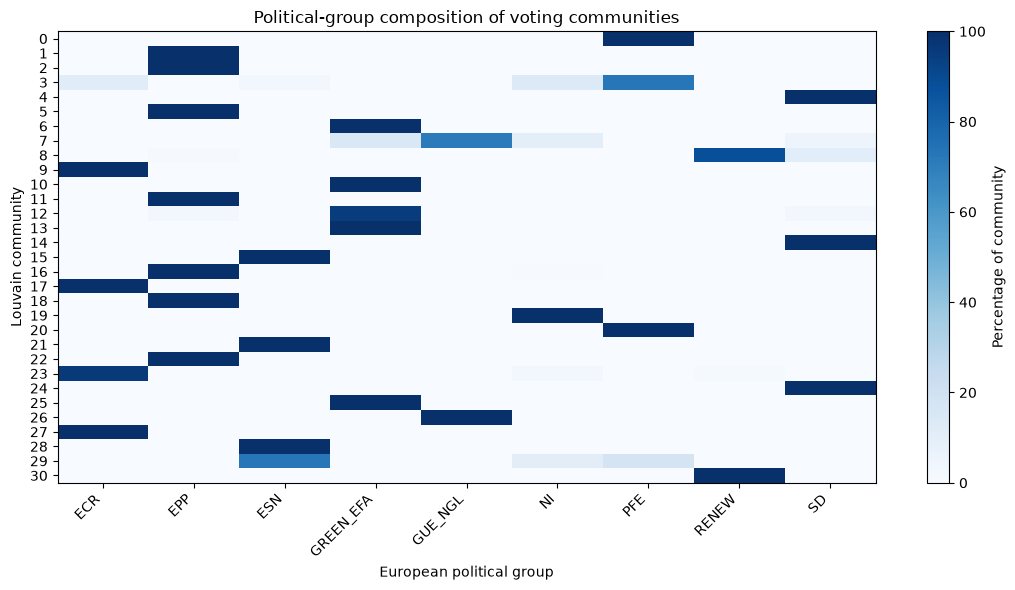

In [21]:

import matplotlib.pyplot as plt

results = member_info.copy()
results["community"] = communities

# Count political-group members per community
comparison = pd.crosstab(
    results["community"],
    results["group_code"]
)

# Convert each community row into percentages
percentages = comparison.div(
    comparison.sum(axis=1),
    axis=0
) * 100

fig, ax = plt.subplots(figsize=(11, 6))

im = ax.imshow(
    percentages.values,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(percentages.columns)))
ax.set_xticklabels(
    percentages.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(range(len(percentages.index)))
ax.set_yticklabels(percentages.index)

ax.set_xlabel("European political group")
ax.set_ylabel("Louvain community")
ax.set_title("Political-group composition of voting communities")

fig.colorbar(im, ax=ax, label="Percentage of community")
plt.tight_layout()
plt.show()


This idk how to interpret yet.
